In [1]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

In [2]:
def get_ingredients(url):
    headers = {
        "User-Agent": "Mozilla/5.0"
    }

    response = requests.get(url, headers=headers)
    soup = BeautifulSoup(response.text, "html.parser")

    ingredients = soup.select(".tasty-recipes-ingredients li")

    ingredient_list = []

    for ingredient in ingredients:
        ingredient_list.append(ingredient.get_text(" ", strip=True))

    return ingredient_list

In [4]:
recipes = {
    # cookies
    "Chocolate Chip Cookies": "https://sallysbakingaddiction.com/chewy-chocolate-chip-cookies/",
    "Maple Brown Sugar Cookies": "https://sallysbakingaddiction.com/maple-brown-sugar-cookies/",
    "Red Velvet Chocolate Chip Cookies": "https://sallysbakingaddiction.com/red-velvet-chocolate-chip-cookies/",

    # breads
    "Homemade Biscuits": "https://sallysbakingaddiction.com/flaky-buttermilk-biscuits/",
    "Cinnamon Swirl Quick Bread": "https://sallysbakingaddiction.com/cinnamon-swirl-quick-bread/",
    "Lemon Blueberry Babka": "https://sallysbakingaddiction.com/lemon-blueberry-babka/",

    # cakes
    "Classic Chiffon Cake": "https://sallysbakingaddiction.com/chiffon-cake/",
    "Homemade Cake Pops": "https://sallysbakingaddiction.com/homemade-cake-pops/",
    "Chocolate Raspberry Cake": "https://sallysbakingaddiction.com/chocolate-raspberry-cake/",

    # brownies and bars
    "Seriously Fudgy Homemade Brownies": "https://sallysbakingaddiction.com/seriously-fudgy-homemade-brownies/",
    "Soft & Chewy Chocolate Chip Cookie bars": "https://sallysbakingaddiction.com/soft-chewy-chocolate-chip-cookie-bars/",
    "S'mores Cookie Bars": "https://sallysbakingaddiction.com/smore-cookie-bars/",

    # pies
    "Strawberry Rhubarb Pie": "https://sallysbakingaddiction.com/strawberry-rhubarb-pie/",
    "Apple Crumble Pie": "https://sallysbakingaddiction.com/apple-crumble-pie/",
    "Pumpkin Pie": "https://sallysbakingaddiction.com/the-great-pumpkin-pie-recipe/"
}

In [5]:
recipe_data = {}

for name, url in recipes.items():
    recipe_data[name] = get_ingredients(url)
    print(name, "-", len(recipe_data[name]), "ingredients")

Chocolate Chip Cookies - 10 ingredients
Maple Brown Sugar Cookies - 14 ingredients
Red Velvet Chocolate Chip Cookies - 12 ingredients
Homemade Biscuits - 9 ingredients
Cinnamon Swirl Quick Bread - 12 ingredients
Lemon Blueberry Babka - 19 ingredients
Classic Chiffon Cake - 14 ingredients
Homemade Cake Pops - 15 ingredients
Chocolate Raspberry Cake - 30 ingredients
Seriously Fudgy Homemade Brownies - 9 ingredients
Soft & Chewy Chocolate Chip Cookie bars - 11 ingredients
S'mores Cookie Bars - 10 ingredients
Strawberry Rhubarb Pie - 12 ingredients
Apple Crumble Pie - 19 ingredients
Pumpkin Pie - 17 ingredients


In [8]:
common_ingredients = [
    "flour",
    "baking soda",
    "baking powder",
    "cornstarch",
    "salt",
    "butter",
    "brown sugar",
    "granulated sugar",
    "powdered sugar",
    "egg",
    "vanilla extract",
    "chocolate chips",
    "cocoa powder",
    "milk",
    "buttermilk",
    "heavy cream",
    "cream cheese",
    "oil",
    "cinnamon",
    "nutmeg",
    "lemon",
    "blueberries",
    "strawberries",
    "raspberries",
    "apples",
    "pumpkin"
]

In [10]:
def clean_ingredients(ingredients):
    cleaned = []

    ingredient_text = " ".join(ingredients).lower()

    for ingredient in common_ingredients:
        if ingredient in ingredient_text:
            cleaned.append(ingredient)

    return cleaned

In [12]:
cleaned_recipe_data = {}

for name, ingredients in recipe_data.items():
    cleaned_recipe_data[name] = clean_ingredients(ingredients)

    print(name)
    print(cleaned_recipe_data[name])
    print()

Chocolate Chip Cookies
['flour', 'baking soda', 'cornstarch', 'salt', 'butter', 'brown sugar', 'granulated sugar', 'egg', 'vanilla extract', 'chocolate chips']

Maple Brown Sugar Cookies
['flour', 'baking soda', 'salt', 'butter', 'brown sugar', 'egg', 'vanilla extract']

Red Velvet Chocolate Chip Cookies
['flour', 'baking soda', 'salt', 'butter', 'brown sugar', 'granulated sugar', 'egg', 'vanilla extract', 'chocolate chips', 'cocoa powder', 'milk', 'buttermilk']

Homemade Biscuits
['flour', 'baking soda', 'baking powder', 'salt', 'butter', 'milk', 'buttermilk']

Cinnamon Swirl Quick Bread
['flour', 'baking soda', 'salt', 'granulated sugar', 'egg', 'vanilla extract', 'milk', 'oil', 'cinnamon']

Lemon Blueberry Babka
['flour', 'salt', 'butter', 'brown sugar', 'granulated sugar', 'egg', 'vanilla extract', 'milk', 'heavy cream', 'lemon', 'blueberries']

Classic Chiffon Cake
['flour', 'baking powder', 'salt', 'granulated sugar', 'egg', 'vanilla extract', 'milk', 'heavy cream', 'cream cheese

In [14]:
G = nx.Graph()

# Add each recipe as a node
for recipe in cleaned_recipe_data:
    G.add_node(recipe)

recipe_names = list(cleaned_recipe_data.keys())

# Compare each pair of recipes
for i in range(len(recipe_names)):
    for j in range(i + 1, len(recipe_names)):

        recipe1 = recipe_names[i]
        recipe2 = recipe_names[j]

        ingredients1 = set(cleaned_recipe_data[recipe1])
        ingredients2 = set(cleaned_recipe_data[recipe2])

        shared = ingredients1.intersection(ingredients2)

        # Connect recipes that share at least 7 ingredients
        if len(shared) >= 7:
            G.add_edge(recipe1, recipe2, weight=len(shared))

In [16]:
print("Number of nodes:", G.number_of_nodes())
print("Number of edges:", G.number_of_edges())

Number of nodes: 15
Number of edges: 49


In [18]:
degree_centrality = nx.degree_centrality(G)

sorted_centrality = sorted(
    degree_centrality.items(),
    key=lambda x: x[1],
    reverse=True
)

for recipe, centrality in sorted_centrality:
    print(recipe, "-", round(centrality, 3))

Chocolate Raspberry Cake - 0.857
Red Velvet Chocolate Chip Cookies - 0.786
Chocolate Chip Cookies - 0.714
Soft & Chewy Chocolate Chip Cookie bars - 0.714
Homemade Cake Pops - 0.643
Apple Crumble Pie - 0.643
Lemon Blueberry Babka - 0.571
Strawberry Rhubarb Pie - 0.429
Cinnamon Swirl Quick Bread - 0.357
Classic Chiffon Cake - 0.286
Seriously Fudgy Homemade Brownies - 0.286
S'mores Cookie Bars - 0.286
Maple Brown Sugar Cookies - 0.214
Homemade Biscuits - 0.143
Pumpkin Pie - 0.071


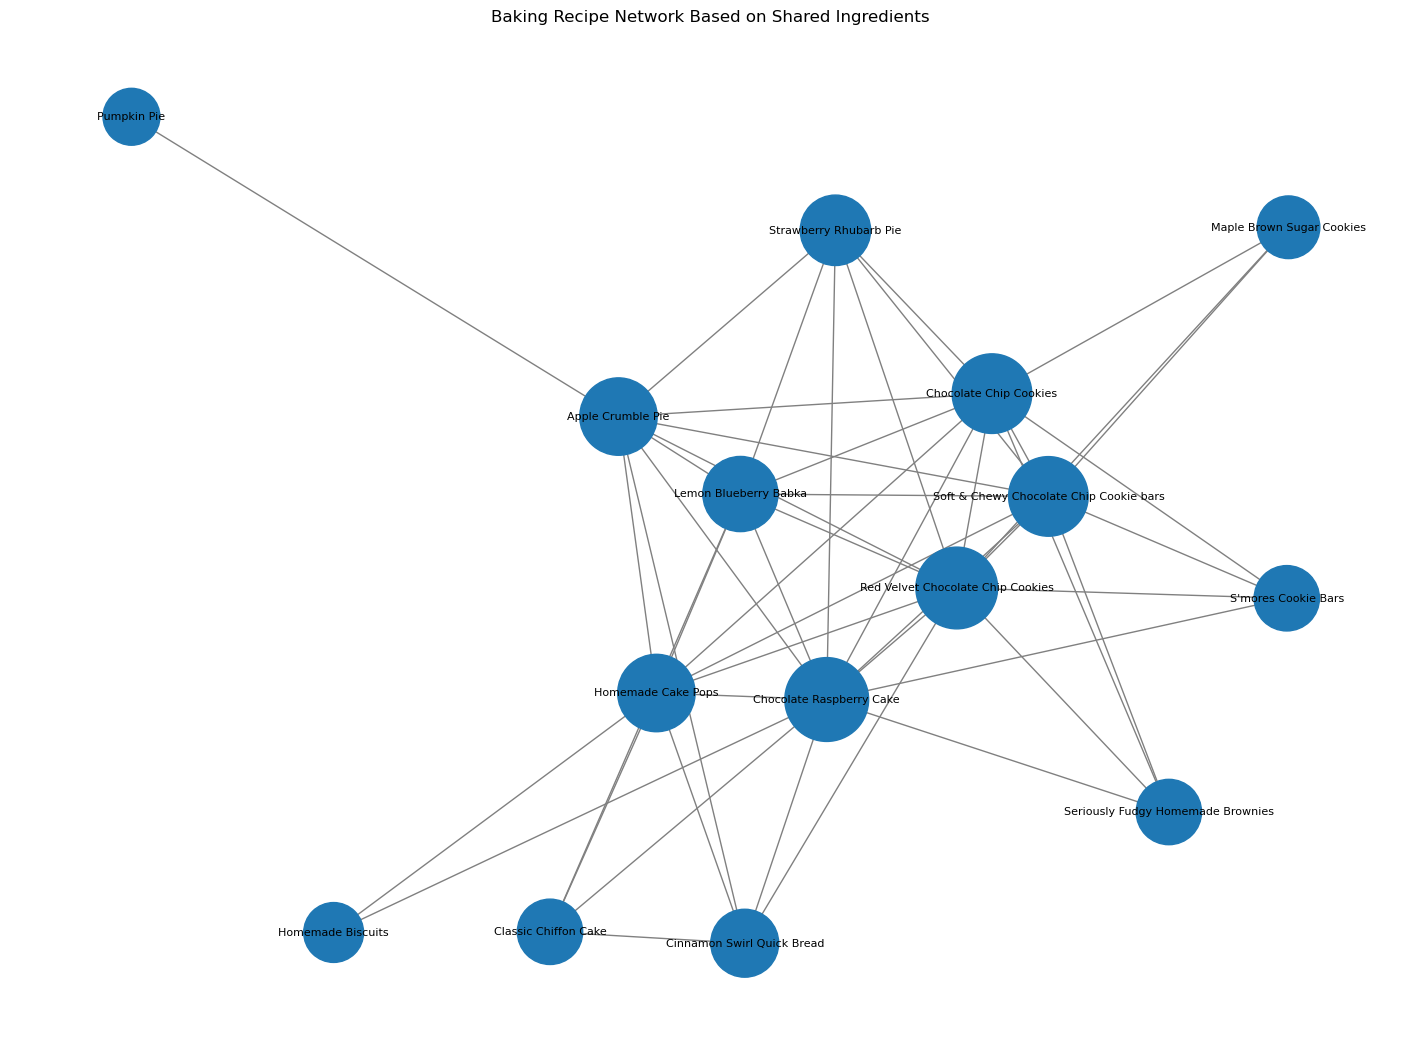

In [ ]:
plt.figure(figsize=(14, 10))
pos = nx.spring_layout(G, seed=42)
node_sizes = [
    1500 + (degree_centrality[node] * 2500)
    for node in G.nodes()
]
nx.draw(
    G,
    pos,
    with_labels=True,
    node_size=node_sizes,
    font_size=8,
    edge_color="gray"
)
plt.title("Baking Recipe Network Based on Shared Ingredients")
plt.show()

In [23]:
results = pd.DataFrame(
    sorted_centrality,
    columns=["Recipe", "Degree Centrality"]
)

results["Degree Centrality"] = results["Degree Centrality"].round(3)

results.head(5)

,Recipe,Degree Centrality
0,Chocolate Raspberry Cake,0.857
1,Red Velvet Chocolate Chip Cookies,0.786
2,Chocolate Chip Cookies,0.714
3,Soft & Chewy Chocolate Chip Cookie bars,0.714
4,Homemade Cake Pops,0.643


In [24]:
for threshold in [4, 5, 6, 7, 8]:
    test_G = nx.Graph()

    for recipe in cleaned_recipe_data:
        test_G.add_node(recipe)

    recipe_names = list(cleaned_recipe_data.keys())

    for i in range(len(recipe_names)):
        for j in range(i + 1, len(recipe_names)):

            recipe1 = recipe_names[i]
            recipe2 = recipe_names[j]

            ingredients1 = set(cleaned_recipe_data[recipe1])
            ingredients2 = set(cleaned_recipe_data[recipe2])

            shared = ingredients1.intersection(ingredients2)

            if len(shared) >= threshold:
                test_G.add_edge(recipe1, recipe2)

    print("Threshold:", threshold, "- Edges:", test_G.number_of_edges())

Threshold: 4 - Edges: 99
Threshold: 5 - Edges: 89
Threshold: 6 - Edges: 71
Threshold: 7 - Edges: 49
Threshold: 8 - Edges: 19
